# 02 · Modelado: línea base, LightGBM y métricas de pronóstico

Proyecto CityBykeNY (DataRush). Se pronostican salidas y llegadas por estación y hora, de un día
para otro, con dos pronósticos: una **línea base** (promedio histórico) y un **LightGBM global
con cuantiles**. Aquí están los tres tramos, la regla de no fuga de información y las métricas en
validación y en la prueba final.

Las métricas miden el error contra la **demanda atendida**, que es lo único que registran los
datos.

## Cómo reproducir desde cero

Desde la raíz del repositorio, con el entorno activado (Python 3.12), en este orden:

```bash
python3.12 -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt -c constraints.txt

python scripts/download_trips.py --desde 202607 --hasta 202609   # unos 3 GB, a data/raw/trips
python scripts/freeze_gbfs.py            # SOLO si falta config/gbfs_congelado.csv (necesita una captura de GBFS)
python scripts/build_tables.py           # limpieza: stations, station_hour, routes y trips
python scripts/run_baseline.py           # promedio histórico: predictions y métricas de validación
python scripts/run_lgbm.py               # LightGBM con cuantiles: predictions y métricas de validación
python scripts/run_simulation.py         # simulación en validación: recommendations y policy_curve
python scripts/run_piso_wape.py          # piso del WAPE y métricas por franja, en validación
```

La prueba final **ya se calificó, una sola vez, el 10 de octubre de 2026**. El comando que lo hizo
fue `python scripts/run_prueba_final.py --usar-prueba-final`; se niega a correr de nuevo si ya
existe `data/processed/prueba_final/reports/metricas_prueba.json`. Este notebook no la recalcula.

Este notebook **no recalcula nada pesado**: lee `data/processed` y los reportes de
`data/processed/reports` que dejaron esos comandos, y muestra tablas y gráficas. Los pasos que corresponden a este notebook son `run_baseline.py`, `run_lgbm.py` y `run_piso_wape.py`.
Para volver a ejecutarlo: `python -m jupyter nbconvert --to notebook --execute --inplace notebooks/02_modelado.ipynb`.

In [1]:
# Raíz del repositorio: funciona si el notebook se abre desde notebooks/ o desde la raíz.
import json
import os
import sys
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "paths.py").exists())
sys.path.insert(0, str(RAIZ))
os.chdir(RAIZ)  # las rutas relativas (config/, data/) se resuelven desde la raíz

import duckdb
import pandas as pd
from IPython.display import Markdown, display

from src.paths import DATA_PROCESSED, DATA_RAW, REPORTS, TZ

pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", None)


def leer_json(ruta):
    return json.loads(Path(ruta).read_text(encoding="utf-8"))


def miles(v, dec=0):
    return f"{v:,.{dec}f}"


def pct(v, dec=1):
    return f"{100 * v:.{dec}f} %"


print("Raíz:", RAIZ.name, "| zona horaria:", TZ)

Raíz: CityBykeNY | zona horaria: America/New_York


In [2]:
# Gráficas: el entorno del proyecto no trae matplotlib, así que se dibujan con Pillow
# y quedan como PNG dentro del notebook (se ven en GitHub sin ejecutar nada).
import io
import math

from IPython.display import Image as PNG
from PIL import Image, ImageDraw, ImageFont

TINTA, GRIS, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
AZUL, NARANJA, VERDE, NEUTRO = "#2a78d6", "#eb6834", "#1baf7a", "#898781"


def fuente(puntos):
    """Una fuente del sistema con acentos; si no hay ninguna, la de Pillow (que no los trae)."""
    for nombre in ("Arial.ttf", "DejaVuSans.ttf", "Helvetica.ttc", "LiberationSans-Regular.ttf", "arial.ttf"):
        try:
            return ImageFont.truetype(nombre, puntos)
        except OSError:
            continue
    return ImageFont.load_default(size=puntos)


def grafica(series, titulo, eje_x, eje_y, marcas_x, lineas_v=(), lineas_h=(), en_pct=False, ancho=860, alto=400):
    """Líneas sobre un solo eje que empieza en cero.

    series: lista de dicts con nombre, x, y, color y, si hay intervalo, bajo y alto.
    marcas_x: lista de (valor, texto). lineas_v y lineas_h: listas de (valor, texto).
    """
    k = 2  # se dibuja al doble para que se vea nítido
    W, H = ancho * k, alto * k
    img = Image.new("RGB", (W, H), FONDO)
    d = ImageDraw.Draw(img)
    f_t, f_n = fuente(15 * k), fuente(12 * k)
    izq, der, arr, aba = 80 * k, 30 * k, 84 * k, 58 * k
    xs = [float(v) for s in series for v in s["x"]]
    ys = [float(v) for s in series for c in ("y", "bajo", "alto") for v in s.get(c, [])] + [float(h) for h, _ in lineas_h]
    x0, x1, y1 = min(xs), max(xs), max(ys) * 1.08
    paso = 10 ** math.floor(math.log10(y1 / 4))
    paso *= next(m for m in (1, 2, 5, 10) if y1 / (paso * m) <= 6)
    px = lambda x: izq + (float(x) - x0) / (x1 - x0) * (W - izq - der)
    py = lambda y: H - aba - float(y) / y1 * (H - arr - aba)
    texto = (lambda v: f"{100 * v:.0f} %") if en_pct else (lambda v: f"{v:,.0f}" if paso >= 1 else f"{v:,.2f}")

    d.text((izq, 10 * k), titulo, fill=TINTA, font=f_t)
    lx = izq
    for s in series:
        d.line([(lx, 44 * k), (lx + 18 * k, 44 * k)], fill=s["color"], width=3 * k)
        d.text((lx + 24 * k, 36 * k), s["nombre"], fill=GRIS, font=f_n)
        lx += 24 * k + d.textlength(s["nombre"], font=f_n) + 22 * k
    d.text((izq, arr - 22 * k), eje_y, fill=GRIS, font=f_n)

    for i in range(int(y1 / paso) + 1):
        v = i * paso
        d.line([(izq, py(v)), (W - der, py(v))], fill=REJILLA if i else "#c3c2b7", width=k)
        t = texto(v)
        d.text((izq - 8 * k - d.textlength(t, font=f_n), py(v) - 8 * k), t, fill=GRIS, font=f_n)
    for v, t in marcas_x:
        d.line([(px(v), H - aba), (px(v), H - aba + 4 * k)], fill="#c3c2b7", width=k)
        d.text((px(v) - d.textlength(t, font=f_n) / 2, H - aba + 8 * k), t, fill=GRIS, font=f_n)
    d.text(((izq + W - der) / 2 - d.textlength(eje_x, font=f_n) / 2, H - 24 * k), eje_x, fill=GRIS, font=f_n)
    for v, t in lineas_v:
        d.line([(px(v), arr), (px(v), H - aba)], fill=NEUTRO, width=k)
        d.text((px(v) + 5 * k, arr + 2 * k), t, fill=GRIS, font=f_n)
    for v, t in lineas_h:
        d.line([(izq, py(v)), (W - der, py(v))], fill=NEUTRO, width=k)
        d.text((izq + 8 * k, py(v) + 5 * k), t, fill=GRIS, font=f_n)

    for i, s in enumerate(series):
        puntos = [(px(x), py(y)) for x, y in zip(s["x"], s["y"])]
        if "bajo" in s:  # intervalo: bigote vertical, corrido unos pixeles para que no se tapen entre series
            corr = (i - (len(series) - 1) / 2) * 5 * k
            for x, lo, hi in zip(s["x"], s["bajo"], s["alto"]):
                d.line([(px(x) + corr, py(lo)), (px(x) + corr, py(hi))], fill=s["color"], width=k)
                for y in (lo, hi):
                    d.line([(px(x) + corr - 3 * k, py(y)), (px(x) + corr + 3 * k, py(y))], fill=s["color"], width=k)
        if len(puntos) > 1:
            d.line(puntos, fill=s["color"], width=2 * k, joint="curve")
        if len(puntos) <= 31:
            for x, y in puntos:
                d.ellipse([x - 5 * k, y - 5 * k, x + 5 * k, y + 5 * k], fill=s["color"], outline=FONDO, width=k)

    salida = io.BytesIO()
    img.save(salida, format="PNG", optimize=True)
    display(PNG(data=salida.getvalue(), width=ancho))

## 1. Tres tramos ordenados en el tiempo

Entrenamiento, validación y prueba final, sin huecos ni traslapes (`config/datos.yaml`). Todo lo
que se decidió (variables, hiperparámetros, número de rondas, reglas del simulador) se decidió
con entrenamiento y validación. La prueba final se usó una sola vez, con todo congelado.

In [3]:
from src.data.datos_config import load_datos

datos = load_datos()
entrada = leer_json(REPORTS / "lgbm_entrada.json")
tramos = entrada["entrada"]["tramos"]
display(pd.DataFrame([
    {"tramo": n, "primer día": str(t.inicio), "último día": str(t.fin), "días": (t.fin - t.inicio).days + 1,
     "filas de estación y hora": miles(tramos[n]["filas"]) if "filas" in tramos[n] else "(no se guarda)",
     "salidas": miles(tramos[n]["salidas"]) if "salidas" in tramos[n] else "(no se guarda)"}
    for n, t in datos.tramos.items()]).set_index("tramo"))

,primer día,último día,días,filas de estación y hora,salidas
tramo,,,,,
entrenamiento,2026-07-01,2026-08-31,62,"3,406,270","10,231,598"
validacion,2026-09-01,2026-09-14,14,"784,929","2,423,931"
prueba,2026-09-15,2026-09-29,15,(no se guarda),(no se guarda)


De la prueba final, la huella de entrada guarda solo las fechas, a propósito.

## 2. Línea base

`src/models/baseline.py`: **promedio histórico por estación, día de la semana y hora local.**
Para validación la historia es el entrenamiento; para la prueba final, entrenamiento más
validación.

- En `predictions`, para la línea base, **`q50` guarda ese promedio: es una media, no una
  mediana**. `q10` y `q90` son los cuantiles empíricos de la misma celda.
- Si una estación no tiene historia, su pronóstico es el promedio del sistema para ese día y hora.
  No es un pronóstico de esa estación, es un marcador (0.6 % de las filas de validación).

## 3. LightGBM global con cuantiles

`src/models/lgbm.py`: seis modelos (salidas y llegadas, cada una con q10, q50 y q90). Es global:
un mismo modelo sirve a todas las estaciones, y la estación entra por sus variables. Para
validación se ajusta con entrenamiento y el número de rondas se fija por parada temprana contra
validación. Para la prueba se vuelve a ajustar con entrenamiento más validación, con
hiperparámetros y rondas ya fijados. Antes de escribir, los cuantiles se recortan en 0 y se
ordenan (q10 ≤ q50 ≤ q90).

In [4]:
variables = entrada["modelo"]["variables"]
grupos = {
    "rezagos y resúmenes a la misma hora (días previos)": [v for v in variables if any(p in v for p in ("_rez_", "_media_7d", "_28d", "_dia_4s")) and "total" not in v],
    "totales de la estación en días previos": [v for v in variables if "total" in v],
    "calendario de la propia fila": [v for v in variables if v in ("hora", "dia_semana", "fin_de_semana", "festivo")],
}
usadas = {v for g in grupos.values() for v in g}
grupos["fijas de la estación (promedios solo del tramo de ajuste)"] = [v for v in variables if v not in usadas]
print(len(variables), "variables:")
for nombre, lista in grupos.items():
    print(f"\n{nombre} ({len(lista)}):\n  " + ", ".join(lista))

42 variables:

rezagos y resúmenes a la misma hora (días previos) (23):
  dep_rez_1d, dep_rez_2d, dep_rez_7d, dep_rez_14d, dep_media_7d, dep_media_28d, dep_q10_28d, dep_q90_28d, dep_media_dia_4s, dep_min_dia_4s, dep_max_dia_4s, arr_rez_1d, arr_rez_2d, arr_rez_7d, arr_rez_14d, arr_media_7d, arr_media_28d, arr_q10_28d, arr_q90_28d, arr_media_dia_4s, arr_min_dia_4s, arr_max_dia_4s, dias_con_historia_28d

totales de la estación en días previos (6):
  dep_total_1d, dep_total_7d, dep_total_media_7d, arr_total_1d, arr_total_7d, arr_total_media_7d

calendario de la propia fila (4):
  hora, dia_semana, fin_de_semana, festivo

fijas de la estación (promedios solo del tramo de ajuste) (9):
  lat, lon, capacidad, dep_media_estacion, dep_media_estacion_hora, dep_media_estacion_tipo_hora, arr_media_estacion, arr_media_estacion_hora, arr_media_estacion_tipo_hora


## 4. Sin fuga de información

Regla: las variables de una fila cuyo día local es D solo pueden depender de filas de
`station_hour` de **días anteriores a D** (más el calendario de la propia fila y lo fijo de la
estación). Los rezagos son de días anteriores, no del mismo día, y van por fecha y hora local, no
por posición.

La regla se prueba, no solo se declara. Cada variable se escribe como un constructor registrado
con `@register` (`src/features/registry.py`) y `tests/test_no_leakage.py` revisa a todos los
registrados con dos experimentos desde un día de corte: cambia los valores, y aparte quita cerca
de la mitad de las filas. Las variables de los días anteriores al corte no deben cambiar en
ninguno de los dos. No se usa clima observado ni ninguna variable externa.

In [5]:
from src.features.registry import load_builders

print("Constructores registrados que revisa tests/test_no_leakage.py:")
for nombre in load_builders():
    print("  -", nombre)

Constructores registrados que revisa tests/test_no_leakage.py:
  - rezagos_misma_hora
  - totales_dias_previos
  - calendario
  - lags_dias_previos


En la prueba final, las filas de LightGBM usan como rezago los conteos observados de días de
prueba ya transcurridos (el rezago de ayer para predecir hoy): es lo que tendría el operador y lo
aprobó el equipo antes de usar la prueba. De la prueba nunca se leyó un valor como objetivo.

## 5. Métricas en validación (1 a 14 de septiembre)

MAE y RMSE en viajes por estación y hora; WAPE (error absoluto total entre demanda total) y
cobertura del intervalo de q10 a q90, cuyo nivel nominal es 80 %. No se usa MAPE: explota con
demanda cercana a cero. Los dos modelos se califican sobre las mismas filas.

In [6]:
from src.models.metrics import NOMINAL_COVERAGE, TARGET_LABELS

MODELOS = {"baseline": "línea base", "lgbm": "LightGBM", "media global": "media global", "permutación": "revuelto entre estaciones"}


def presentar(m):
    """Tabla legible a partir de las filas de métricas (una por modelo, objetivo y grupo)."""
    t = pd.DataFrame({
        "objetivo": m["target"].map(TARGET_LABELS), "grupo": m["group"], "modelo": m["model"].map(MODELOS),
        "filas": m["n"].map(miles), "MAE": m["mae"].round(3), "RMSE": m["rmse"].round(3), "WAPE": m["wape"].map(pct),
        "cobertura": m["coverage"].map(pct), "ancho del intervalo": m["mean_width"].round(2).astype(str)})
    t.loc[(m["mean_width"] == 0).to_numpy(), ["cobertura", "ancho del intervalo"]] = "no aplica"  # pronóstico de un solo valor
    return t.set_index(["objetivo", "grupo", "modelo"])


val = pd.read_parquet(REPORTS / "metricas_validacion.parquet")
display(presentar(val[val["group_by"] == "general"].sort_values(["target", "model"], ascending=[False, True])))

filas    MAE   RMSE    WAPE cobertura ancho del intervalo
objetivo grupo modelo                                                                 
salidas  todas línea base  784,929  1.518  2.962  49.1 %    80.0 %                3.42
               LightGBM    784,929  1.414  2.913  45.8 %    84.0 %                4.05
llegadas todas línea base  784,929  1.516  2.957  49.2 %    80.0 %                3.41
               LightGBM    784,929  1.412  2.897  45.8 %    84.3 %                4.04

In [7]:
display(presentar(val[(val["group_by"] == "tipo_de_dia") & (val["target"] == "dep")].sort_values(["group", "model"])))

filas    MAE   RMSE    WAPE cobertura ancho del intervalo
objetivo grupo         modelo                                                                 
salidas  festivo       línea base   56,080  1.884  3.885  66.3 %    75.0 %                 3.3
                       LightGBM     56,080  1.722  3.652  60.6 %    77.9 %                3.79
         fin de semana línea base  224,628  1.527  2.893  53.4 %    81.4 %                3.67
                       LightGBM    224,628  1.388  2.695  48.5 %    84.2 %                4.11
         laborable     línea base  504,221  1.473  2.873  45.8 %    80.0 %                3.32
                       LightGBM    504,221  1.391  2.913  43.2 %    84.6 %                4.04

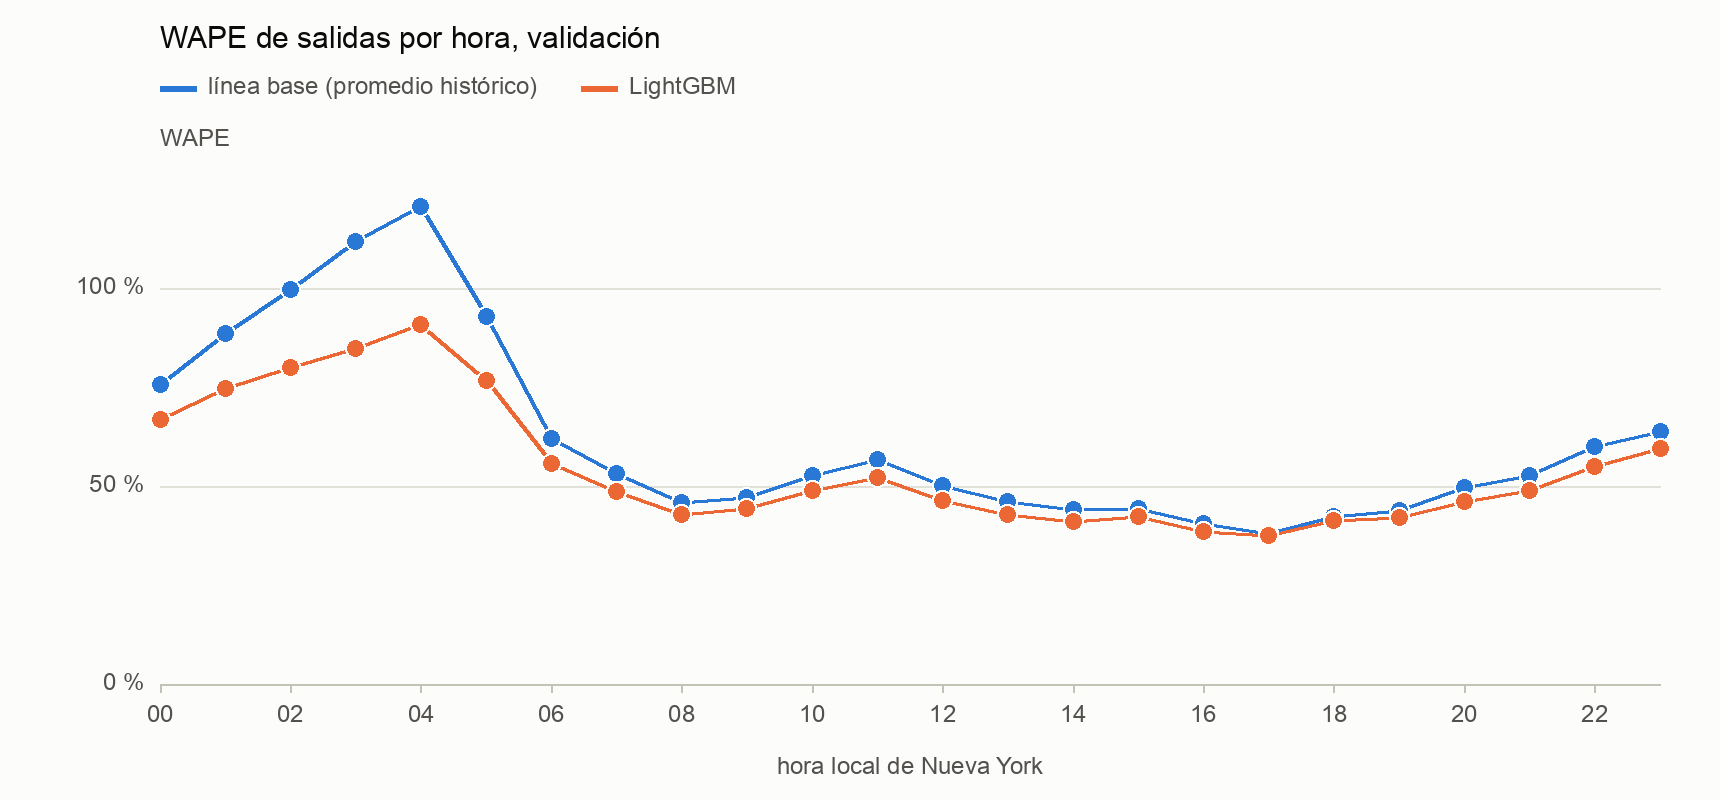

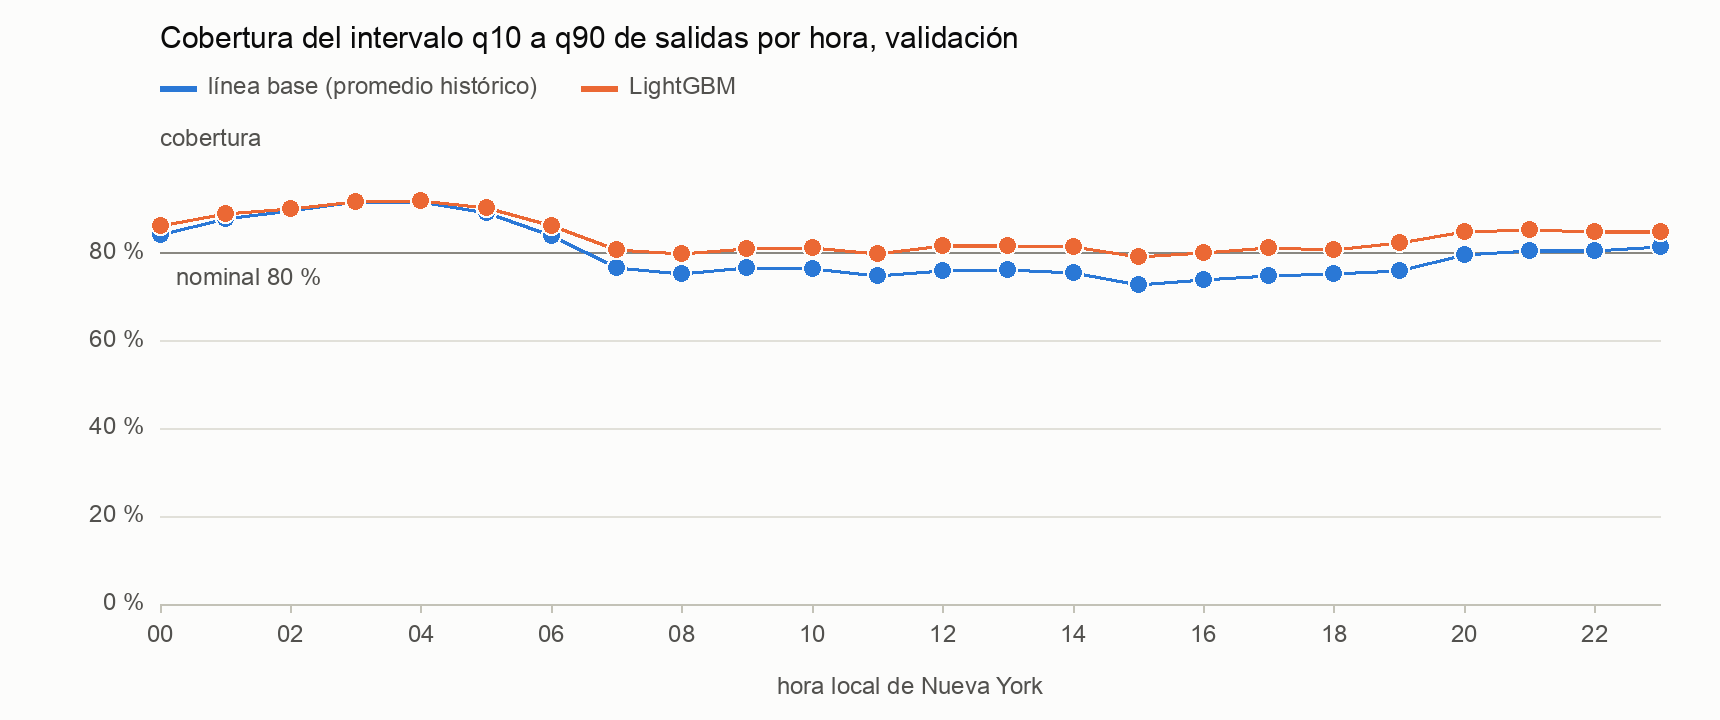

h,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
WAPE línea base,75.6 %,88.6 %,99.8 %,111.8 %,120.7 %,93.0 %,61.9 %,53.2 %,45.8 %,47.3 %,52.8 %,56.6 %,50.2 %,46.2 %,44.1 %,44.3 %,40.5 %,38.0 %,42.2 %,43.8 %,49.6 %,52.7 %,60.0 %,63.7 %
WAPE LightGBM,66.9 %,74.7 %,80.0 %,84.9 %,90.8 %,76.7 %,55.7 %,48.7 %,42.7 %,44.2 %,49.0 %,52.3 %,46.3 %,42.9 %,41.0 %,42.2 %,38.7 %,37.5 %,41.3 %,42.0 %,46.2 %,49.0 %,55.1 %,59.4 %
cobertura línea base,84.2 %,87.8 %,89.6 %,91.6 %,91.7 %,89.3 %,83.9 %,76.6 %,75.4 %,76.6 %,76.6 %,74.8 %,76.0 %,76.3 %,75.4 %,72.9 %,73.9 %,74.9 %,75.2 %,75.9 %,79.6 %,80.6 %,80.5 %,81.5 %
cobertura LightGBM,86.2 %,88.9 %,90.1 %,91.6 %,92.0 %,90.3 %,86.2 %,80.7 %,79.9 %,80.9 %,81.3 %,79.9 %,81.6 %,81.7 %,81.4 %,79.2 %,80.1 %,81.2 %,80.8 %,82.4 %,84.8 %,85.4 %,84.9 %,84.9 %


In [8]:
hora = val[(val["group_by"] == "hora") & (val["target"] == "dep")].assign(h=lambda d: d["group"].astype(int)).sort_values("h")
b, l = hora[hora["model"] == "baseline"], hora[hora["model"] == "lgbm"]
marcas = [(h, f"{h:02d}") for h in range(0, 24, 2)]
grafica([{"nombre": "línea base (promedio histórico)", "x": b["h"], "y": b["wape"], "color": AZUL},
         {"nombre": "LightGBM", "x": l["h"], "y": l["wape"], "color": NARANJA}],
        "WAPE de salidas por hora, validación", "hora local de Nueva York", "WAPE", marcas, en_pct=True)
grafica([{"nombre": "línea base (promedio histórico)", "x": b["h"], "y": b["coverage"], "color": AZUL},
         {"nombre": "LightGBM", "x": l["h"], "y": l["coverage"], "color": NARANJA}],
        "Cobertura del intervalo q10 a q90 de salidas por hora, validación", "hora local de Nueva York", "cobertura",
        marcas, lineas_h=[(NOMINAL_COVERAGE, "nominal 80 %")], en_pct=True, alto=360)
display(pd.DataFrame({"WAPE línea base": b.set_index("h")["wape"].map(pct), "WAPE LightGBM": l.set_index("h")["wape"].map(pct),
                      "cobertura línea base": b.set_index("h")["coverage"].map(pct), "cobertura LightGBM": l.set_index("h")["coverage"].map(pct)}).T)

Cómo leerlo sin engañarse:

- **El `q50` de la línea base es una media y el de LightGBM es una mediana condicional.** La
  media no minimiza el error absoluto, así que parte de la ventaja de LightGBM en MAE y WAPE
  viene de ahí. Por eso se mira también el RMSE, donde la ventaja es menor.
- **La cobertura general es un promedio que esconde las horas.** De noche sube porque casi todo
  es cero y el intervalo lo cubre sin mérito; en las horas de más uso baja del 80 % nominal en la
  línea base. Ninguno de los dos es un intervalo calibrado hora por hora, y el de LightGBM cubre
  más en parte porque es más ancho (ver la columna de ancho).
- **El WAPE es muy alto de madrugada**, cuando casi no hay viajes (el de la línea base pasa de
  100 %; el de LightGBM llega a 91 %). Siempre se cita con su hora.
- En días laborables de validación el RMSE de LightGBM es un poco mayor que el de la línea base
  (2.913 contra 2.873), aunque su MAE y su WAPE son menores.
- "Festivo" es un solo día en validación (Labor Day, 7 de septiembre): no generaliza.
- Las horas de una estación cerrada cuentan como error, y solo se mide demanda atendida.

## 6. Piso del WAPE: ¿49 % es mucho?

A nivel de estación y hora la demanda es pequeña y ruidosa (un tercio de las filas está en cero),
así que un WAPE alto no dice por sí solo que el pronóstico sea malo. `scripts/run_piso_wape.py`
lo compara, sobre las mismas filas de validación, con dos pronósticos sin información: la media
global del entrenamiento para todas las estaciones, y el pronóstico de LightGBM revuelto entre
estaciones.

In [9]:
piso = pd.DataFrame(leer_json(REPORTS / "piso_wape.json")["metricas"])
orden = list(MODELOS)
general = piso[piso["group_by"] == "general"].assign(o=lambda d: d["model"].map(orden.index)).sort_values(["target", "o"], ascending=[False, True])
display(presentar(general).drop(columns=["cobertura", "ancho del intervalo"]))
print("Salidas, por franja de operación de hoy (mañana 06 a 14, tarde 14 a 22, noche 22 a 06):")
franja = piso[(piso["group_by"] == "franja") & (piso["target"] == "dep") & piso["model"].isin(["baseline", "lgbm", "media global"])]
display(franja.assign(modelo=franja["model"].map(MODELOS)).pivot(index="group", columns="modelo", values="wape").map(pct))

filas    MAE   RMSE     WAPE
objetivo grupo modelo                                                   
salidas  todas línea base                 784,929  1.518  2.962   49.1 %
               LightGBM                   784,929  1.414  2.913   45.8 %
               media global               784,929  3.581  5.941  115.9 %
               revuelto entre estaciones  784,929  3.968  7.350  128.5 %
llegadas todas línea base                 784,929  1.516  2.957   49.2 %
               LightGBM                   784,929  1.412  2.897   45.8 %
               media global               784,929  3.576  5.965  116.1 %
               revuelto entre estaciones  784,929  3.971  7.410  128.9 %

Salidas, por franja de operación de hoy (mañana 06 a 14, tarde 14 a 22, noche 22 a 06):


modelo,LightGBM,línea base,media global
group,,,
manana,46.7 %,50.5 %,105.3 %
noche,65.2 %,74.8 %,280.2 %
tarde,41.4 %,43.3 %,91.4 %


Los dos pronósticos quedan muy por debajo de los pisos sin información (más de 115 %). La
distancia entre la línea base y LightGBM es pequeña al lado de esa.

## 7. Prueba final (15 a 29 de septiembre), usada una sola vez

Calificada el 10 de octubre de 2026 con las mismas predicciones de `predictions.parquet`, sin
reentrenar ni ajustar nada después de verla. Las cifras salen de
`data/processed/prueba_final/reports/metricas_prueba.json` y de `validacion_y_prueba.json`.

In [10]:
prueba_json = leer_json(DATA_PROCESSED / "prueba_final" / "reports" / "metricas_prueba.json")
print("Calificada (UTC):", prueba_json["calificado_utc"], "| filas:", miles(prueba_json["filas"]["prueba"]))
prueba = pd.DataFrame(prueba_json["metricas"])
general_p = prueba[prueba["group_by"] == "general"].assign(o=lambda d: d["model"].map(orden.index)).sort_values(["target", "o"], ascending=[False, True])
display(presentar(general_p))

Calificada (UTC): 2026-10-10T18:35:47+00:00 | filas: 838,128


filas    MAE   RMSE     WAPE  cobertura ancho del intervalo
objetivo grupo modelo                                                                     
salidas  todas línea base    838,128  1.573  3.186   55.8 %     83.0 %                3.45
               LightGBM      838,128  1.395  2.906   49.5 %     84.9 %                4.21
               media global  838,128  3.532  5.969  125.3 %  no aplica           no aplica
llegadas todas línea base    838,128  1.575  3.184   56.0 %     83.0 %                3.45
               LightGBM      838,128  1.393  2.885   49.5 %     85.4 %                 4.2
               media global  838,128  3.533  5.994  125.7 %  no aplica           no aplica

In [11]:
# Validación contra prueba final, salidas (la misma tabla que lee el dashboard).
vyp = leer_json(REPORTS / "validacion_y_prueba.json")
filas = [f for f in vyp["filas"] if f["clave"].startswith(("wape_", "mae_", "cobertura_"))]
fmt = lambda f, v: pct(v) if f["unidad"] == "pct" else f"{v:.3f}"
display(pd.DataFrame([{"métrica (salidas)": f["afirmacion"], "validación": fmt(f, f["validacion"]), "prueba final": fmt(f, f["prueba"])}
                      for f in filas]).set_index("métrica (salidas)"))
print("Salidas en la prueba final, WAPE por franja:")
fr = prueba[(prueba["group_by"] == "franja") & (prueba["target"] == "dep")]
display(fr.assign(modelo=fr["model"].map(MODELOS)).pivot(index="group", columns="modelo", values="wape").map(pct))

,validación,prueba final
métrica (salidas),,
"WAPE de salidas, promedio histórico",49.1 %,55.8 %
"WAPE de salidas, modelo (LightGBM)",45.8 %,49.5 %
"WAPE de salidas, media global (piso sin modelo)",115.9 %,125.3 %
"Cobertura del intervalo de salidas (nominal 80 %), promedio histórico",80.0 %,83.0 %
"Cobertura del intervalo de salidas (nominal 80 %), modelo (LightGBM)",84.0 %,84.9 %
"MAE de salidas (viajes por estación y hora), promedio histórico",1.518,1.573
"MAE de salidas (viajes por estación y hora), modelo (LightGBM)",1.414,1.395


Salidas en la prueba final, WAPE por franja:


modelo,LightGBM,línea base,media global
group,,,
manana,48.4 %,54.0 %,110.8 %
noche,75.7 %,91.2 %,353.1 %
tarde,45.8 %,51.0 %,96.7 %


## Qué se concluye y qué no

- LightGBM tiene **menos error de pronóstico** que el promedio histórico en los dos tramos, en
  MAE, RMSE y WAPE generales. La diferencia es modesta y, en MAE y WAPE, parte se debe a que se compara
  una mediana contra una media.
- El WAPE de los dos sube de validación a la prueba; el de la línea base sube más (el MAE de
  LightGBM no sube). No se
  investigó la causa después de ver la prueba, porque la prueba no se usa para decidir nada.
- La cobertura queda por encima del 80 % nominal en la prueba para los dos, con las mismas
  salvedades por hora que en validación. No son intervalos calibrados.
- **Menos error de pronóstico no es el criterio de éxito del proyecto.** El criterio es operativo:
  horas de estación en riesgo en la simulación con un presupuesto fijo de bicis. Si este
  pronóstico se traduce o no en menos riesgo simulado está en `03_evaluacion_y_simulacion.ipynb`.
- Todo esto mide demanda atendida. Una estación vacía registra cero salidas aunque hubiera
  gente queriendo una bici; ni la línea base ni el modelo corrigen eso.